# Car Price Prediction with Machine Learning

## Project Overview

This project aims to predict the selling price of used cars using machine learning regression techniques. The dataset contains vehicle information such as manufacturing year, present price, kilometres driven, fuel type, transmission, and ownership details.

The project covers data preprocessing, exploratory data analysis, feature engineering, regression model development, and model evaluation.

## Objectives

- Analyze car-related features and their relationship with selling prices.
- Clean and preprocess the dataset.
- Create meaningful features to improve prediction.
- Train and compare regression models using Scikit-learn.
- Evaluate model performance using appropriate regression metrics.
- Demonstrate how machine learning can support real-world used-car price estimation.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 120

df = pd.read_csv("/content/car data.csv")

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nDataset columns:")
print(df.columns.tolist())

display(df.head())

Dataset loaded successfully!
Number of rows: 301
Number of columns: 9

Dataset columns:
['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Driven_kms', 'Fuel_Type', 'Selling_type', 'Transmission', 'Owner']


,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


## Dataset Understanding

This section examines the structure, data types, statistical properties, missing values, and duplicate records in the dataset. Understanding the data before training a machine learning model helps identify preprocessing requirements and potential data-quality issues.

In [3]:
print("Dataset information:")
df.info()

print("\nMissing values in each column:")
display(df.isnull().sum().to_frame(name="Missing Values"))

print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

print("\nStatistical summary:")
display(df.describe().T)

print("\nUnique values in categorical columns:")
for column in df.select_dtypes(include="object").columns:
    print(f"{column}: {df[column].nunique()} unique values")

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Driven_kms     301 non-null    int64  
 5   Fuel_Type      301 non-null    object 
 6   Selling_type   301 non-null    object 
 7   Transmission   301 non-null    object 
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 21.3+ KB

Missing values in each column:


,Missing Values
Car_Name,0
Year,0
Selling_Price,0
Present_Price,0
Driven_kms,0
Fuel_Type,0
Selling_type,0
Transmission,0
Owner,0



Number of duplicate rows:
2

Statistical summary:


,count,mean,std,min,25%,50%,75%,max
Year,301.0,2013.627907,2.891554,2003.00,2012.0,2014.0,2016.0,2018.0
Selling_Price,301.0,4.661296,5.082812,0.10,0.9,3.6,6.0,35.0
Present_Price,301.0,7.628472,8.642584,0.32,1.2,6.4,9.9,92.6
Driven_kms,301.0,36947.205980,38886.883882,500.00,15000.0,32000.0,48767.0,500000.0
Owner,301.0,0.043189,0.247915,0.00,0.0,0.0,0.0,3.0



Unique values in categorical columns:
Car_Name: 98 unique values
Fuel_Type: 3 unique values
Selling_type: 2 unique values
Transmission: 2 unique values


## Data Cleaning and Preprocessing

Data cleaning improves the quality of the dataset before analysis and model training. This section standardizes column names, removes duplicate records, checks missing values, and verifies data types.

Duplicate records will be removed to reduce redundant observations. Missing values, if any, will be handled appropriately rather than ignored.

In [4]:
# Standardize column names
df.columns = df.columns.str.strip()

# Remove duplicate records
duplicates_before = df.duplicated().sum()
df = df.drop_duplicates().copy()

# Remove rows with missing target values
df = df.dropna(subset=["Selling_Price"]).copy()

# Convert numeric columns to appropriate types
numeric_columns = [
    "Year",
    "Selling_Price",
    "Present_Price",
    "Driven_kms",
    "Owner"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

# Handle missing values
df = df.dropna(subset=numeric_columns).copy()

# Clean categorical text values
categorical_columns = [
    "Car_Name",
    "Fuel_Type",
    "Selling_type",
    "Transmission"
]

for column in categorical_columns:
    df[column] = df[column].astype("string").str.strip()

df = df.dropna(subset=categorical_columns).copy()
df = df.reset_index(drop=True)

print("Data cleaning completed!")
print("Duplicate rows originally found:", duplicates_before)
print("Dataset shape after cleaning:", df.shape)

print("\nRemaining missing values:")
display(df.isnull().sum().to_frame(name="Missing Values"))

display(df.head())

Data cleaning completed!
Duplicate rows originally found: 2
Dataset shape after cleaning: (299, 9)

Remaining missing values:


,Missing Values
Car_Name,0
Year,0
Selling_Price,0
Present_Price,0
Driven_kms,0
Fuel_Type,0
Selling_type,0
Transmission,0
Owner,0


,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


## Exploratory Data Analysis

Exploratory Data Analysis (EDA) helps us understand the distribution of car selling prices and the relationships between vehicle features and their prices. Visualizations can reveal trends, unusual observations, and potentially useful features for machine learning.

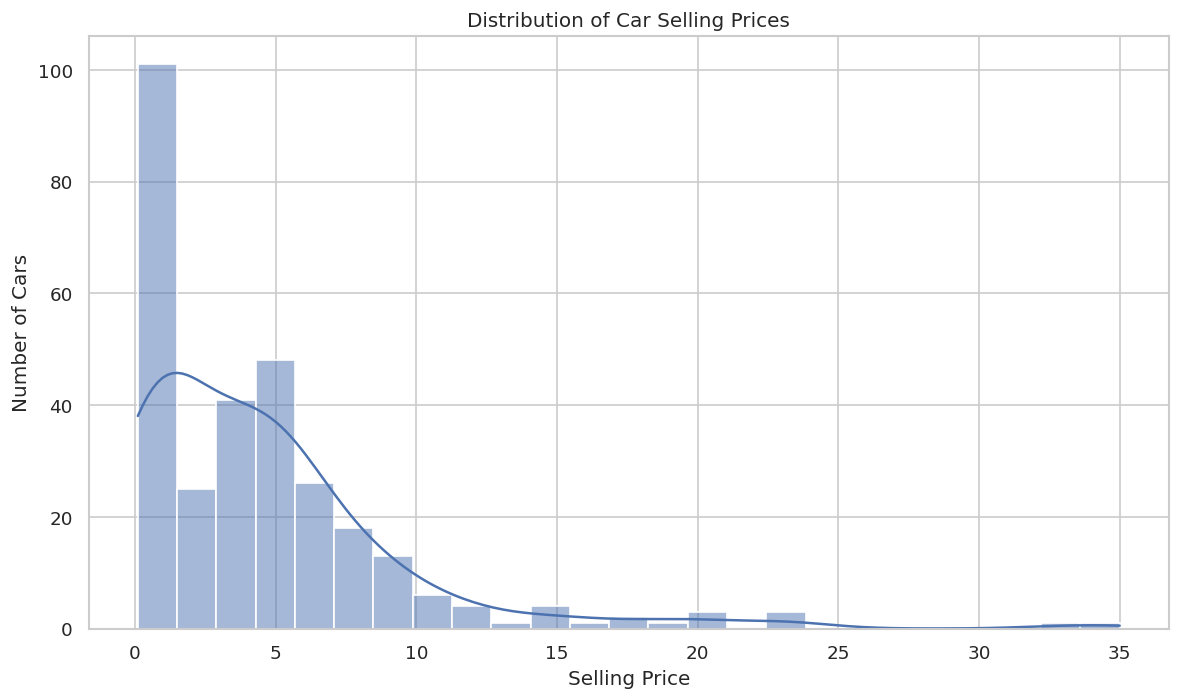

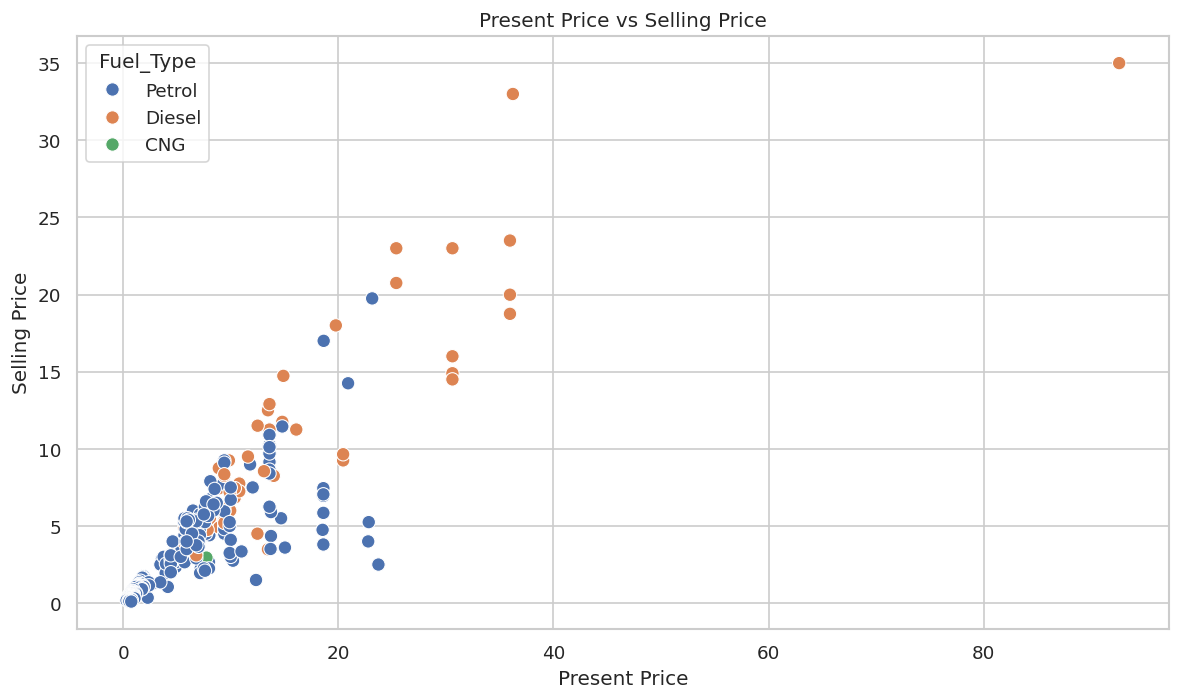

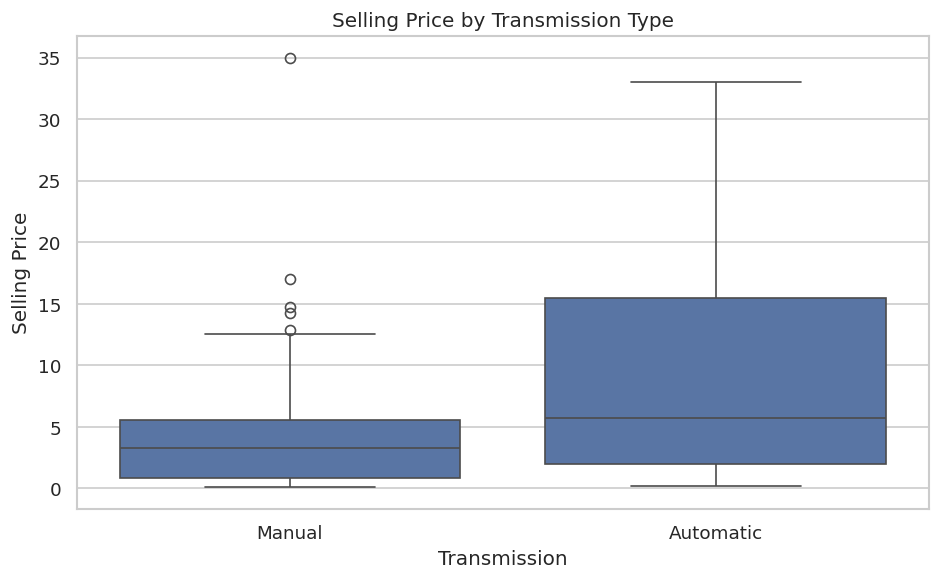

EDA visualizations generated successfully.


In [5]:
# Distribution of selling prices
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x="Selling_Price", bins=25, kde=True)
plt.title("Distribution of Car Selling Prices")
plt.xlabel("Selling Price")
plt.ylabel("Number of Cars")
plt.tight_layout()
plt.show()

# Selling price versus present price
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x="Present_Price",
    y="Selling_Price",
    hue="Fuel_Type",
    s=65
)
plt.title("Present Price vs Selling Price")
plt.xlabel("Present Price")
plt.ylabel("Selling Price")
plt.tight_layout()
plt.show()

# Selling price by transmission
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Transmission", y="Selling_Price")
plt.title("Selling Price by Transmission Type")
plt.xlabel("Transmission")
plt.ylabel("Selling Price")
plt.tight_layout()
plt.show()

print("EDA visualizations generated successfully.")

## Feature Engineering

Feature engineering creates useful input variables from existing data. In this project, the manufacturing year will be used to calculate the approximate age of each car. Car age may help the model learn how vehicle age relates to resale value.

The reference year will be based on the latest manufacturing year available in the dataset, plus one year, to keep the analysis consistent with the dataset.

Reference year used: 2019
Feature engineering completed.


,Car_Name,Year,Car_Age,Present_Price,Selling_Price
0,ritz,2014,5,5.59,3.35
1,sx4,2013,6,9.54,4.75
2,ciaz,2017,2,9.85,7.25
3,wagon r,2011,8,4.15,2.85
4,swift,2014,5,6.87,4.60
5,vitara brezza,2018,1,9.83,9.25
6,ciaz,2015,4,8.12,6.75
7,s cross,2015,4,8.61,6.50
8,ciaz,2016,3,8.89,8.75
9,ciaz,2015,4,8.92,7.45


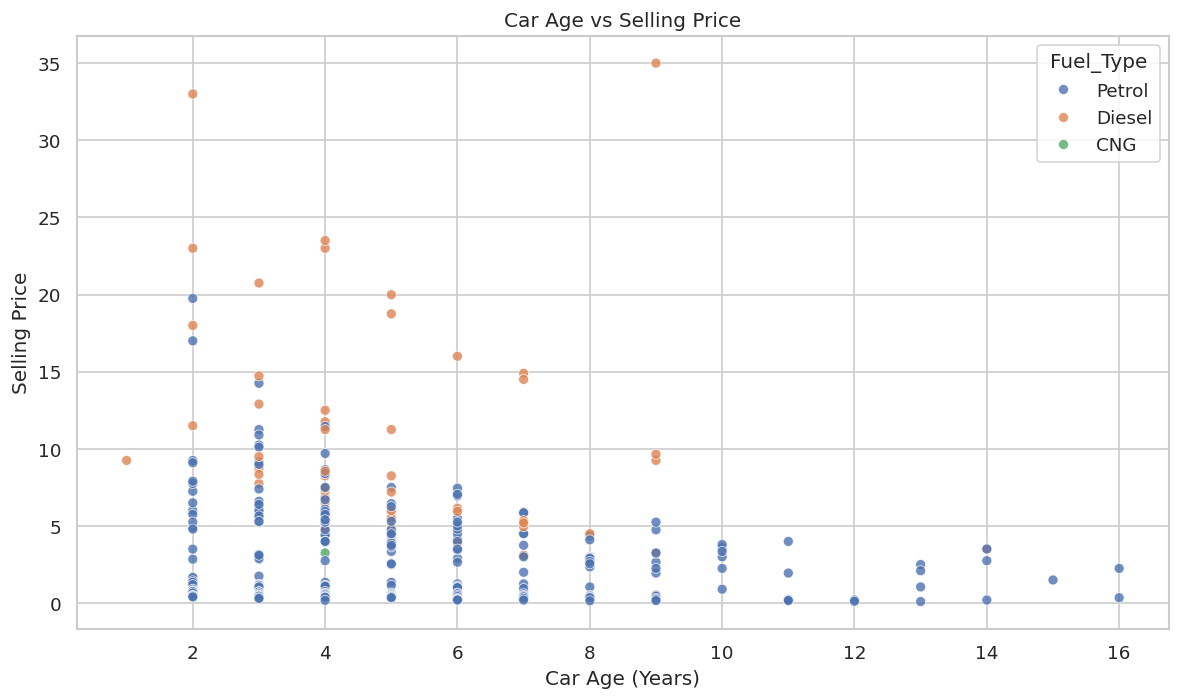

In [6]:
# Use a consistent reference year based on the dataset
reference_year = int(df["Year"].max()) + 1

df["Car_Age"] = reference_year - df["Year"]

print("Reference year used:", reference_year)
print("Feature engineering completed.")

display(
    df[["Car_Name", "Year", "Car_Age", "Present_Price", "Selling_Price"]]
    .head(10)
)

# Analyze the relationship between car age and selling price
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x="Car_Age",
    y="Selling_Price",
    hue="Fuel_Type",
    alpha=0.8
)
plt.title("Car Age vs Selling Price")
plt.xlabel("Car Age (Years)")
plt.ylabel("Selling Price")
plt.tight_layout()
plt.show()

## Model Preparation and Data Preprocessing

The dataset will now be prepared for machine learning. The selling price is the target variable, while the remaining vehicle characteristics will be used as input features.

Categorical variables will be converted into numerical representations using one-hot encoding. The data will be divided into training and testing sets so that model performance can be evaluated on unseen records.

The `Car_Name` column will be retained as a feature because different car models can have different resale values.

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

# Separate input features and target
X = df.drop(columns=["Selling_Price", "Year"])
y = df["Selling_Price"]

# Identify categorical and numerical columns
categorical_features = X.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

# Preprocess categorical features
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        ("numerical", "passthrough", numerical_features)
    ]
)

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Model preparation completed.")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)

Model preparation completed.
Training records: 239
Testing records: 60
Categorical features: ['Car_Name', 'Fuel_Type', 'Selling_type', 'Transmission']
Numerical features: ['Present_Price', 'Driven_kms', 'Owner', 'Car_Age']


## Machine Learning Model Training

In this section, two regression algorithms will be trained to predict used-car selling prices.

- **Linear Regression:** Establishes a baseline model by learning linear relationships between the input features and selling price.
- **Random Forest Regressor:** Combines multiple decision trees to learn more complex relationships in the data.

Both models will use the same training and testing split to ensure a fair comparison. Preprocessing will be performed through machine learning pipelines to prevent data leakage.

In [8]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# Create model pipelines
linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression())
    ]
)

random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "regressor",
            RandomForestRegressor(
                n_estimators=300,
                random_state=42,
                min_samples_leaf=2
            )
        )
    ]
)

# Train both models
linear_model.fit(X_train, y_train)
random_forest_model.fit(X_train, y_train)

print("Both models trained successfully!")

Both models trained successfully!


## Model Evaluation

The trained models will be evaluated on the unseen test dataset using three regression metrics.

- **MAE (Mean Absolute Error):** Measures the average absolute difference between actual and predicted prices. Lower is better.
- **RMSE (Root Mean Squared Error):** Penalizes larger prediction errors more heavily. Lower is better.
- **R² Score:** Measures how well the model explains variation in the target variable. A higher score generally indicates a better fit, although it can be negative on test data.

The metrics will be used together to compare the models rather than relying on a single score.

In [9]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score

# Generate predictions
linear_predictions = linear_model.predict(X_test)
rf_predictions = random_forest_model.predict(X_test)

# Calculate evaluation metrics
results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [
        mean_absolute_error(y_test, linear_predictions),
        mean_absolute_error(y_test, rf_predictions)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, linear_predictions)),
        np.sqrt(mean_squared_error(y_test, rf_predictions))
    ],
    "R2 Score": [
        r2_score(y_test, linear_predictions),
        r2_score(y_test, rf_predictions)
    ]
})

print("Model Evaluation Results")
display(results.round(3))

# Select the model with the lower MAE
best_model_name = results.loc[results["MAE"].idxmin(), "Model"]

best_model = (
    linear_model
    if best_model_name == "Linear Regression"
    else random_forest_model
)

best_predictions = best_model.predict(X_test)

print("Model with the lowest test MAE:", best_model_name)

Model Evaluation Results


,Model,MAE,RMSE,R2 Score
0,Linear Regression,1.412,2.432,0.771
1,Random Forest,1.358,3.241,0.592


Model with the lowest test MAE: Random Forest


## Actual vs Predicted Prices

This visualization compares the actual selling prices with the prices predicted by the selected model. Predictions closer to the diagonal reference line indicate better agreement between actual and predicted values.

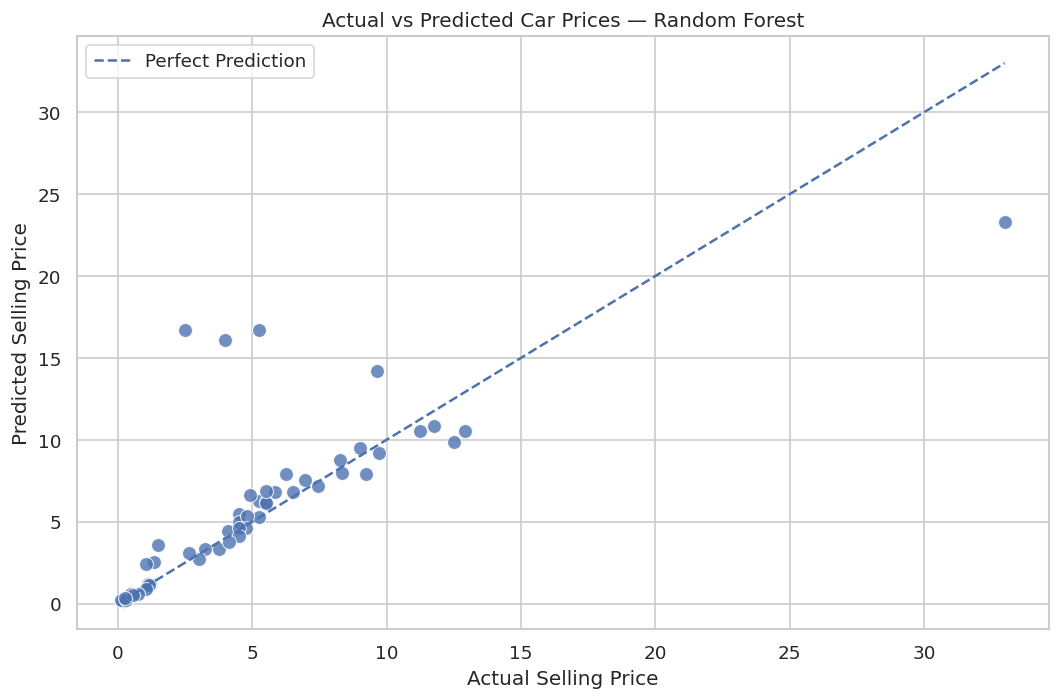

In [10]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=y_test,
    y=best_predictions,
    s=70,
    alpha=0.8
)

min_price = min(y_test.min(), best_predictions.min())
max_price = max(y_test.max(), best_predictions.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--",
    label="Perfect Prediction"
)

plt.title(f"Actual vs Predicted Car Prices — {best_model_name}")
plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")
plt.legend()
plt.tight_layout()
plt.show()

## Sample Car Price Prediction

The selected model will be used to predict selling prices for sample car records. These predictions demonstrate how a trained regression model can estimate a vehicle's selling price from its available characteristics.

The examples use feature values from the dataset to keep the predictions consistent with the type of data used during training.

In [11]:
# Select sample records from the test dataset
sample_cars = X_test.head(5).copy()

# Predict their selling prices
sample_predictions = best_model.predict(sample_cars)

prediction_results = sample_cars.copy()
prediction_results["Actual Selling Price"] = y_test.loc[sample_cars.index].values
prediction_results["Predicted Selling Price"] = sample_predictions
prediction_results["Absolute Error"] = np.abs(
    prediction_results["Actual Selling Price"]
    - prediction_results["Predicted Selling Price"]
)

print("Sample Car Price Predictions")
display(prediction_results.round(2))

Sample Car Price Predictions


,Car_Name,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner,Car_Age,Actual Selling Price,Predicted Selling Price,Absolute Error
281,city,11.80,9010,Petrol,Dealer,Manual,0,3,8.99,9.49,0.50
265,city,9.40,19434,Diesel,Dealer,Manual,0,3,8.35,7.96,0.39
164,Hero Passion Pro,0.55,1000,Petrol,Individual,Manual,0,3,0.45,0.46,0.01
9,ciaz,8.92,42367,Diesel,Dealer,Manual,0,4,7.45,7.18,0.27
77,corolla altis,22.83,80000,Petrol,Dealer,Automatic,0,9,5.25,16.69,11.44


## Feature Importance Analysis

Feature importance helps identify which input variables contribute most to the Random Forest model's predictions. Because categorical variables are one-hot encoded, the importance values correspond to the transformed feature names.

These values indicate predictive usefulness within the fitted model; they do not establish that a feature causes a change in car prices.

Top 15 features by Random Forest importance


,Feature,Importance
92,numerical__Present_Price,0.9167
95,numerical__Car_Age,0.0569
93,numerical__Driven_kms,0.0125
70,categorical__Car_Name_fortuner,0.0026
75,categorical__Car_Name_innova,0.0023
91,categorical__Transmission_Manual,0.0017
89,categorical__Selling_type_Individual,0.0014
59,categorical__Car_Name_city,0.0010
90,categorical__Transmission_Automatic,0.0009
60,categorical__Car_Name_corolla altis,0.0008


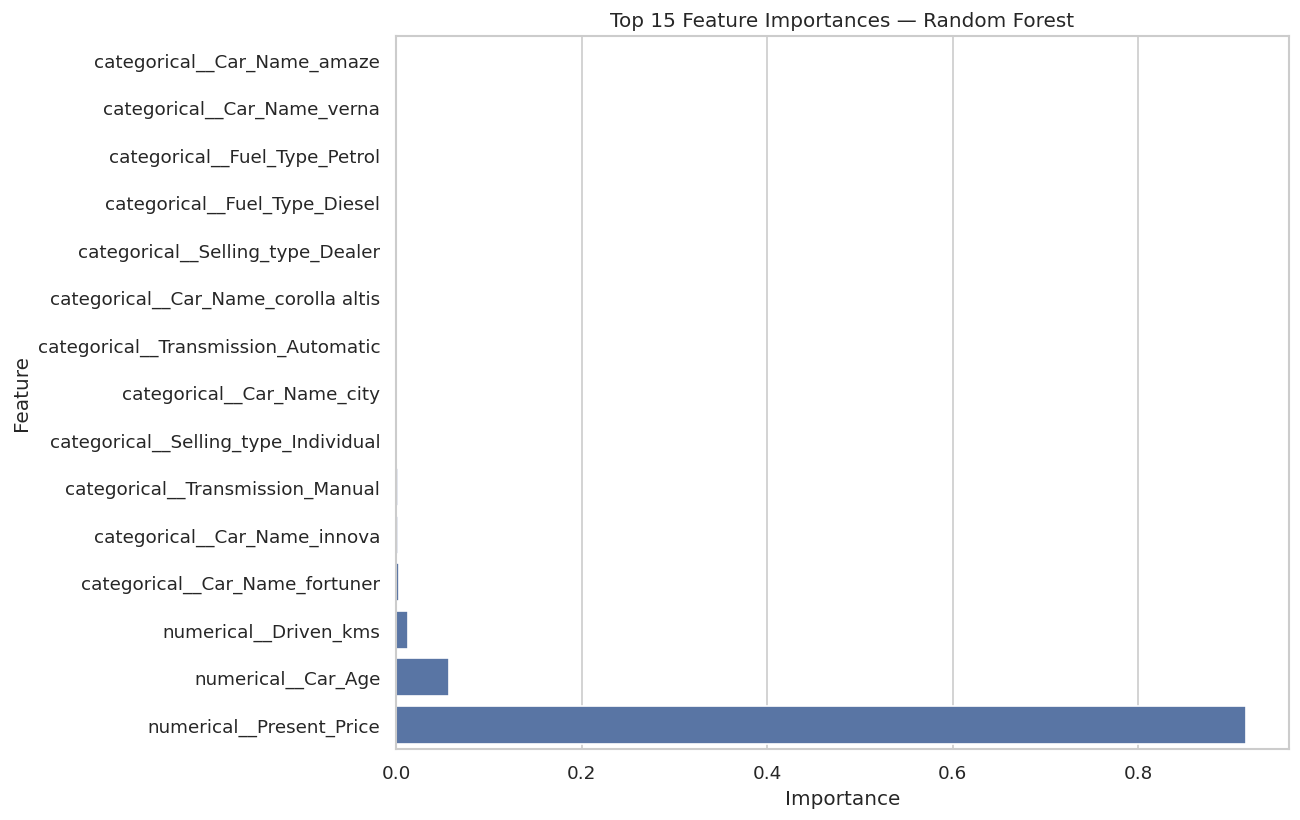

In [12]:
# Extract the fitted preprocessing and Random Forest components
fitted_preprocessor = random_forest_model.named_steps["preprocessor"]
fitted_forest = random_forest_model.named_steps["regressor"]

feature_names = fitted_preprocessor.get_feature_names_out()
importances = fitted_forest.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

print("Top 15 features by Random Forest importance")
display(feature_importance.head(15).round(4))

plt.figure(figsize=(11, 7))
top_features = feature_importance.head(15).sort_values("Importance")
sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)
plt.title("Top 15 Feature Importances — Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## Real-World Applications

Machine learning-based car price prediction can support several practical activities:

- **Used-car marketplaces:** Provide an initial estimated selling price for listed vehicles.
- **Buyers:** Help compare a car's asking price with estimates based on similar available records.
- **Dealers:** Support inventory valuation and preliminary pricing decisions.
- **Sellers:** Offer a starting point when deciding a listing price.

## Limitations

- The dataset contains a limited number of records and may not represent the entire used-car market.
- The available features do not include every important factor, such as detailed vehicle condition, accident history, service records, or regional market differences.
- Predictions depend on the dataset's pricing patterns and may not reflect current market prices.
- Model performance on a test split does not guarantee equally accurate predictions for all cars.

The model should be treated as a decision-support tool, not as a guarantee of a car's actual market value.

## Conclusion

This project demonstrates how Python and machine learning can be used to predict used-car selling prices from vehicle characteristics.

The workflow included data cleaning, exploratory data analysis, feature engineering, categorical feature encoding, train-test splitting, regression model training, and evaluation using MAE, RMSE, and R² score.

Linear Regression and Random Forest Regressor were compared using the same test dataset. The evaluation results help identify which model performed better on the available test records.

The project also demonstrates sample price predictions and examines feature importance to improve understanding of the model's behaviour.

Overall, this project provides practical experience with data preprocessing, regression, model evaluation, and the real-world use of machine learning in price estimation. Predictions should be interpreted with the limitations of the dataset in mind.